Mounted at /content/drive
Dataset Shape: (50000, 2)

First Five Reviews:


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive



Cleaned Reviews:


,review,cleaned_review,sentiment
0,One of the other reviewers has mentioned that ...,one of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,a wonderful little production the filming tech...,positive
2,I thought this was a wonderful way to spend ti...,i thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,basically there s a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",petter mattei s love in the time of money is a...,positive



VADER Sentiment Distribution:


,Count
vader_sentiment,
positive,3335
negative,1619
neutral,46


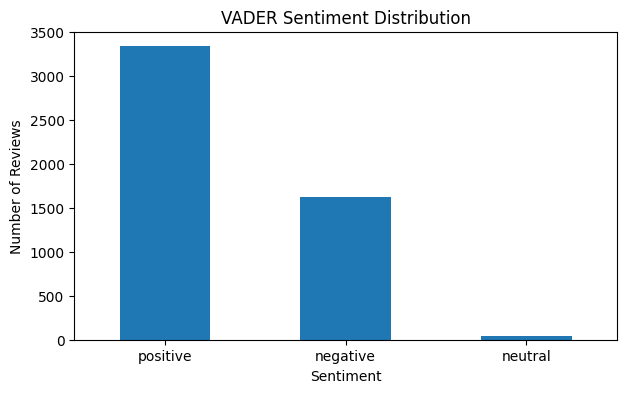


Model Evaluation
Accuracy: 0.8977

Classification Report:
              precision    recall  f1-score   support

    negative       0.91      0.89      0.90      5000
    positive       0.89      0.91      0.90      5000

    accuracy                           0.90     10000
   macro avg       0.90      0.90      0.90     10000
weighted avg       0.90      0.90      0.90     10000



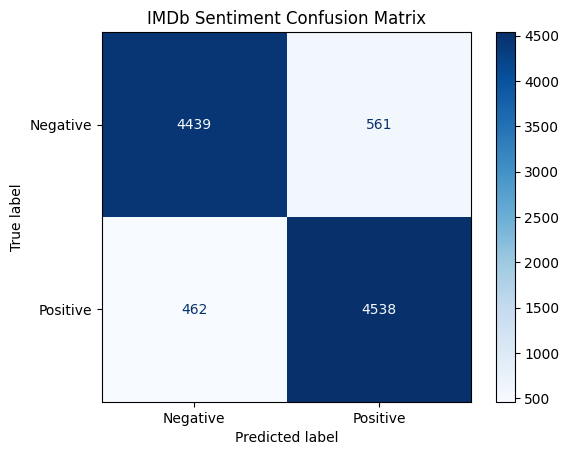

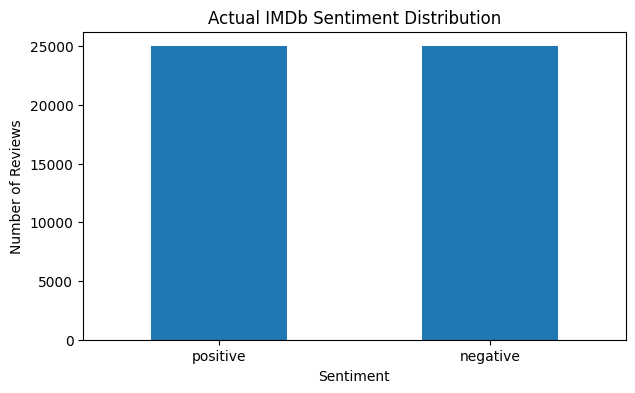

Enter a movie review: This movie has great VFX
Predicted Sentiment: POSITIVE


In [2]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import nltk

from google.colab import drive
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay
)
from nltk.sentiment.vader import SentimentIntensityAnalyzer

# 1. Connect Google Drive
drive.mount('/content/drive')

# 2. Load IMDb Dataset
file_path = '/content/drive/MyDrive/Colab Notebooks/PBA PRACTICAL FILE/IMDB Dataset.csv'
df = pd.read_csv(file_path)

print("Dataset Shape:", df.shape)
print("\nFirst Five Reviews:")
display(df.head())

# 3. Text Preprocessing
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r'<.*?>', ' ', text)
    text = re.sub(r'http\S+|www\S+', ' ', text)
    text = re.sub(r'[^a-z\s]', ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

df = df.dropna(subset=['review', 'sentiment']).copy()
df['cleaned_review'] = df['review'].apply(clean_text)
df['sentiment'] = df['sentiment'].str.lower().str.strip()

df = df[df['sentiment'].isin(['positive', 'negative'])]

print("\nCleaned Reviews:")
display(df[['review', 'cleaned_review', 'sentiment']].head())

# 4. VADER Sentiment Analysis
nltk.download('vader_lexicon', quiet=True)
analyzer = SentimentIntensityAnalyzer()

def vader_sentiment(text):
    score = analyzer.polarity_scores(text)['compound']
    if score >= 0.05:
        return 'positive'
    elif score <= -0.05:
        return 'negative'
    return 'neutral'

# Analyze up to 5,000 reviews with VADER
sample_df = df.sample(n=min(5000, len(df)), random_state=42).copy()
sample_df['vader_sentiment'] = sample_df['cleaned_review'].apply(
    vader_sentiment
)

print("\nVADER Sentiment Distribution:")
display(sample_df['vader_sentiment'].value_counts().to_frame('Count'))

sample_df['vader_sentiment'].value_counts().plot(
    kind='bar', figsize=(7, 4)
)
plt.title('VADER Sentiment Distribution')
plt.xlabel('Sentiment')
plt.ylabel('Number of Reviews')
plt.xticks(rotation=0)
plt.show()

# 5. Prepare Data for Machine Learning
X = df['cleaned_review']
y = df['sentiment']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# 6. Convert Text into TF-IDF Features
tfidf = TfidfVectorizer(
    max_features=10000,
    stop_words='english',
    ngram_range=(1, 2)
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

# 7. Train Logistic Regression Model
model = LogisticRegression(max_iter=1000)
model.fit(X_train_tfidf, y_train)

y_pred = model.predict(X_test_tfidf)

# 8. Evaluate Model
print("\nModel Evaluation")
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

# 9. Confusion Matrix
cm = confusion_matrix(
    y_test, y_pred, labels=['negative', 'positive']
)
display_matrix = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Negative', 'Positive']
)
display_matrix.plot(cmap='Blues')
plt.title('IMDb Sentiment Confusion Matrix')
plt.show()

# 10. Plot Actual Sentiment Distribution
df['sentiment'].value_counts().plot(
    kind='bar', figsize=(7, 4)
)
plt.title('Actual IMDb Sentiment Distribution')
plt.xlabel('Sentiment')
plt.ylabel('Number of Reviews')
plt.xticks(rotation=0)
plt.show()

# 11. Test a New Review
new_review = input("Enter a movie review: ")
cleaned = clean_text(new_review)
new_vector = tfidf.transform([cleaned])
prediction = model.predict(new_vector)[0]

print("Predicted Sentiment:", prediction.upper())